In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\Desktop\8.to_9_nov\Hospital_Emergency_Room_Dashboard-main\Hospital Emergency Room Data.csv")
print(df.head(10))

    Patient Id Patient Admission Date Patient First Inital Patient Last Name  \
0  145-39-5406       20-03-2024 08:47                    H         Glasspool   
1  316-34-3057       15-06-2024 11:29                    X           Methuen   
2  897-46-3852       20-06-2024 09:13                    P         Schubuser   
3  358-31-9711         4/2/2024 22:34                    U          Titcombe   
4  289-26-0537         4/9/2024 17:48                    Y       Gionettitti   
5  255-51-2877       20-04-2023 00:13                    H              Buff   
6  465-97-0990       23-08-2023 08:26                    F            Perrat   
7  157-31-7520       29-07-2023 16:57                    K           Gwillim   
8  432-34-5614       19-02-2024 06:54                    E          Dewhirst   
9  609-17-8678        11/10/2024 5:25                    M             Crebo   

  Patient Gender  Patient Age                   Patient Race  \
0              M           69                          

In [ ]:
# 4. Business questions to answer
# These questions will make your project useful in a Data Analyst interview.
# 1. What is the total number of emergency-room visits?
# 2. What is the average patient waiting time?
# 3. What percentage of patients were admitted?
# 4. Which department received the highest referrals?
# 5. Which month had the highest patient visits?
# 6. Which day had the highest patient visits?
# 7. What is the average waiting time by admission status?
# 8. What is the average patient satisfaction score?
# 9. Which age groups have the highest number of visits?

In [ ]:
## Step 3 – Understand the dataset

In [3]:
print(df.info())
print(df.describe())
print("column name")
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 9216 entries, 0 to 9215
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient Id                  9216 non-null   str    
 1   Patient Admission Date      9216 non-null   str    
 2   Patient First Inital        9216 non-null   str    
 3   Patient Last Name           9216 non-null   str    
 4   Patient Gender              9216 non-null   str    
 5   Patient Age                 9216 non-null   int64  
 6   Patient Race                9216 non-null   str    
 7   Department Referral         3816 non-null   str    
 8   Patient Admission Flag      9216 non-null   bool   
 9   Patient Satisfaction Score  2517 non-null   float64
 10  Patient Waittime            9216 non-null   int64  
 11  Patient Admission Flag.1    9216 non-null   bool   
dtypes: bool(2), float64(1), int64(2), str(7)
memory usage: 1.2 MB
None
       Patient Age  Patient Satisf

In [ ]:
## Step 4 – Data quality checks

In [4]:
# Missing values and percentages
missing = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)
display(missing)

,Missing_Count,Missing_Percent
Patient Satisfaction Score,6699,72.69
Department Referral,5400,58.59
Patient Id,0,0.00
Patient Admission Date,0,0.00
Patient Last Name,0,0.00
Patient First Inital,0,0.00
Patient Age,0,0.00
Patient Gender,0,0.00
Patient Race,0,0.00
Patient Admission Flag,0,0.00


In [ ]:
## Step 5 – Clean column names and remove direct identifiers

Patient ID, first initial and last name are identifiers,
not useful analytical features for this project. 
Keep them out of the analysis dataframe. 
We also remove the second admission-flag column
only after confirming it is identical to the first.

In [5]:
# Drop duplicate flag only if the two columns are exactly identical
if df["Patient Admission Flag"].equals(df["Patient Admission Flag.1"]):
    data = df.drop(columns=["Patient Admission Flag.1"])
print(data)


       Patient Id Patient Admission Date Patient First Inital  \
0     145-39-5406       20-03-2024 08:47                    H   
1     316-34-3057       15-06-2024 11:29                    X   
2     897-46-3852       20-06-2024 09:13                    P   
3     358-31-9711         4/2/2024 22:34                    U   
4     289-26-0537         4/9/2024 17:48                    Y   
...           ...                    ...                  ...   
9211  313-21-4953       28-08-2024 17:38                    J   
9212  226-92-3412       28-06-2024 23:12                    G   
9213  412-85-3832       16-05-2024 17:06                    V   
9214  708-91-2439       14-05-2024 23:43                    S   
9215  249-47-9666          1/3/2024 8:50                    Y   

     Patient Last Name Patient Gender  Patient Age  \
0            Glasspool              M           69   
1              Methuen              M            4   
2            Schubuser              F           56   
3  

In [6]:
# Remove direct identifiers from the analysis dataset
identifier_cols = ["Patient Id", "Patient First Inital", "Patient Last Name"]
data = df.drop(columns=[c for c in identifier_cols if c in data.columns])
print("remove/n",data)


remove/n      Patient Admission Date Patient Gender  Patient Age  \
0          20-03-2024 08:47              M           69   
1          15-06-2024 11:29              M            4   
2          20-06-2024 09:13              F           56   
3            4/2/2024 22:34              F           24   
4            4/9/2024 17:48           Male            5   
...                     ...            ...          ...   
9211       28-08-2024 17:38           Male           42   
9212       28-06-2024 23:12           Male           19   
9213       16-05-2024 17:06           Male           14   
9214       14-05-2024 23:43           Male           73   
9215          1/3/2024 8:50           Male           35   

                       Patient Race Department Referral  \
0                             White                 NaN   
1     Native American/Alaska Native                 NaN   
2                  African American    General Practice   
3     Native American/Alaska Native    General

In [7]:
# Standardize gender labels
df["Patient Gender"] = df["Patient Gender"].replace({
    "M": "Male", "F": "Female"
})
print(df)

       Patient Id Patient Admission Date Patient First Inital  \
0     145-39-5406       20-03-2024 08:47                    H   
1     316-34-3057       15-06-2024 11:29                    X   
2     897-46-3852       20-06-2024 09:13                    P   
3     358-31-9711         4/2/2024 22:34                    U   
4     289-26-0537         4/9/2024 17:48                    Y   
...           ...                    ...                  ...   
9211  313-21-4953       28-08-2024 17:38                    J   
9212  226-92-3412       28-06-2024 23:12                    G   
9213  412-85-3832       16-05-2024 17:06                    V   
9214  708-91-2439       14-05-2024 23:43                    S   
9215  249-47-9666          1/3/2024 8:50                    Y   

     Patient Last Name Patient Gender  Patient Age  \
0            Glasspool           Male           69   
1              Methuen           Male            4   
2            Schubuser         Female           56   
3  

In [8]:
# Convert admission flag to a readable category
df["Patient Admission Flag"] = df["Patient Admission Flag"].map({
    True: "Admitted", False: "Not Admitted"
})

print("Patient Admission Flag",df)

Patient Admission Flag        Patient Id Patient Admission Date Patient First Inital  \
0     145-39-5406       20-03-2024 08:47                    H   
1     316-34-3057       15-06-2024 11:29                    X   
2     897-46-3852       20-06-2024 09:13                    P   
3     358-31-9711         4/2/2024 22:34                    U   
4     289-26-0537         4/9/2024 17:48                    Y   
...           ...                    ...                  ...   
9211  313-21-4953       28-08-2024 17:38                    J   
9212  226-92-3412       28-06-2024 23:12                    G   
9213  412-85-3832       16-05-2024 17:06                    V   
9214  708-91-2439       14-05-2024 23:43                    S   
9215  249-47-9666          1/3/2024 8:50                    Y   

     Patient Last Name Patient Gender  Patient Age  \
0            Glasspool           Male           69   
1              Methuen           Male            4   
2            Schubuser         Fem

In [9]:
display(df.head())

,Patient Id,Patient Admission Date,Patient First Inital,Patient Last Name,Patient Gender,Patient Age,Patient Race,Department Referral,Patient Admission Flag,Patient Satisfaction Score,Patient Waittime,Patient Admission Flag.1
0,145-39-5406,20-03-2024 08:47,H,Glasspool,Male,69,White,NaN,Not Admitted,10.0,39,False
1,316-34-3057,15-06-2024 11:29,X,Methuen,Male,4,Native American/Alaska Native,NaN,Admitted,NaN,27,True
2,897-46-3852,20-06-2024 09:13,P,Schubuser,Female,56,African American,General Practice,Admitted,9.0,55,True
3,358-31-9711,4/2/2024 22:34,U,Titcombe,Female,24,Native American/Alaska Native,General Practice,Admitted,8.0,31,True
4,289-26-0537,4/9/2024 17:48,Y,Gionettitti,Male,5,African American,Orthopedics,Not Admitted,NaN,10,False


In [ ]:
## Step 6 – Convert admission date into datetime

# The source mixes hyphen and slash date formats. The hyphen examples are day-month-year, while slash dates such as `4/2/2024` cannot be interpreted with certainty from the text alone.

# **Initial assumption:** use `dayfirst=True`. 
# If the data provider confirms slash dates are month/day/year, change it to `False`,
# rerun this cell and all date-based analysis. Document the confirmed convention in your project.

In [10]:
DAY_FIRST = True  # Change to False only if the data owner confirms month-first slash dates

df["Patient Admission Date"] = pd.to_datetime(
    data["Patient Admission Date"],
    format="mixed",
    dayfirst=DAY_FIRST,
    errors="coerce"
)

print("Unparsed dates:", df["Patient Admission Date"].isna().sum())


Unparsed dates: 0


In [12]:
df["Admission Year"] = df["Patient Admission Date"].dt.year
df["Admission Month"] = df["Patient Admission Date"].dt.month
df["Admission Month Name"] = df["Patient Admission Date"].dt.strftime("%b")
df["Admission Day"] = df["Patient Admission Date"].dt.day_name()
df["Admission Hour"] = df["Patient Admission Date"].dt.hour
df["Admission Date Only"] = df["Patient Admission Date"].dt.date

print(df[["Patient Admission Date", "Admission Year", "Admission Month Name",
              "Admission Day", "Admission Hour"]].head())

  Patient Admission Date  Admission Year Admission Month Name Admission Day  \
0    2024-03-20 08:47:00            2024                  Mar     Wednesday   
1    2024-06-15 11:29:00            2024                  Jun      Saturday   
2    2024-06-20 09:13:00            2024                  Jun      Thursday   
3    2024-02-04 22:34:00            2024                  Feb        Sunday   
4    2024-09-04 17:48:00            2024                  Sep     Wednesday   

   Admission Hour  
0               8  
1              11  
2               9  
3              22  
4              17  


In [ ]:
## Step 7 – Handle missing values carefully

In [13]:
print(df.isnull().sum())

Patient Id                       0
Patient Admission Date           0
Patient First Inital             0
Patient Last Name                0
Patient Gender                   0
Patient Age                      0
Patient Race                     0
Department Referral           5400
Patient Admission Flag           0
Patient Satisfaction Score    6699
Patient Waittime                 0
Patient Admission Flag.1         0
Admission Year                   0
Admission Month                  0
Admission Month Name             0
Admission Day                    0
Admission Hour                   0
Admission Date Only              0
dtype: int64


In [14]:
# Referral missingness may mean 'Not Recorded' rather than 'No Referral'.
df["Department Referral"] = df["Department Referral"].fillna("Not Recorded")
print(df.head())

    Patient Id Patient Admission Date Patient First Inital Patient Last Name  \
0  145-39-5406    2024-03-20 08:47:00                    H         Glasspool   
1  316-34-3057    2024-06-15 11:29:00                    X           Methuen   
2  897-46-3852    2024-06-20 09:13:00                    P         Schubuser   
3  358-31-9711    2024-02-04 22:34:00                    U          Titcombe   
4  289-26-0537    2024-09-04 17:48:00                    Y       Gionettitti   

  Patient Gender  Patient Age                   Patient Race  \
0           Male           69                          White   
1           Male            4  Native American/Alaska Native   
2         Female           56               African American   
3         Female           24  Native American/Alaska Native   
4           Male            5               African American   

  Department Referral Patient Admission Flag  Patient Satisfaction Score  \
0        Not Recorded           Not Admitted              

In [15]:
# Satisfaction is missing for many records. Do NOT replace it with zero or the mean.
# Keep missing values and analyze satisfaction only where a score exists.
print("Satisfaction scores available:", df["Patient Satisfaction Score"].notna().sum())
print("Satisfaction scores missing:", df["Patient Satisfaction Score"].isna().sum())

Satisfaction scores available: 2517
Satisfaction scores missing: 6699


In [ ]:
## Step 8 – Create key performance indicators (KPIs)

In [16]:
total_visits = len(df)
avg_wait = df["Patient Waittime"].mean()
admitted_count = (df["Patient Admission Flag"] == "Admitted").sum()
admission_rate = admitted_count / total_visits * 100
avg_age = df["Patient Age"].mean()
avg_satisfaction = df["Patient Satisfaction Score"].mean()

kpis = pd.DataFrame({
    "KPI": ["Total ER Visits", "Average Wait Time (minutes)",
            "Admissions", "Admission Rate (%)", "Average Patient Age",
            "Average Satisfaction (available scores only)"],
    "Value": [total_visits, round(avg_wait, 2), admitted_count,
              round(admission_rate, 2), round(avg_age, 2),
              round(avg_satisfaction, 2)]
})
print(kpis)


                                            KPI    Value
0                               Total ER Visits  9216.00
1                   Average Wait Time (minutes)    35.26
2                                    Admissions  4612.00
3                            Admission Rate (%)    50.04
4                           Average Patient Age    39.86
5  Average Satisfaction (available scores only)     4.99


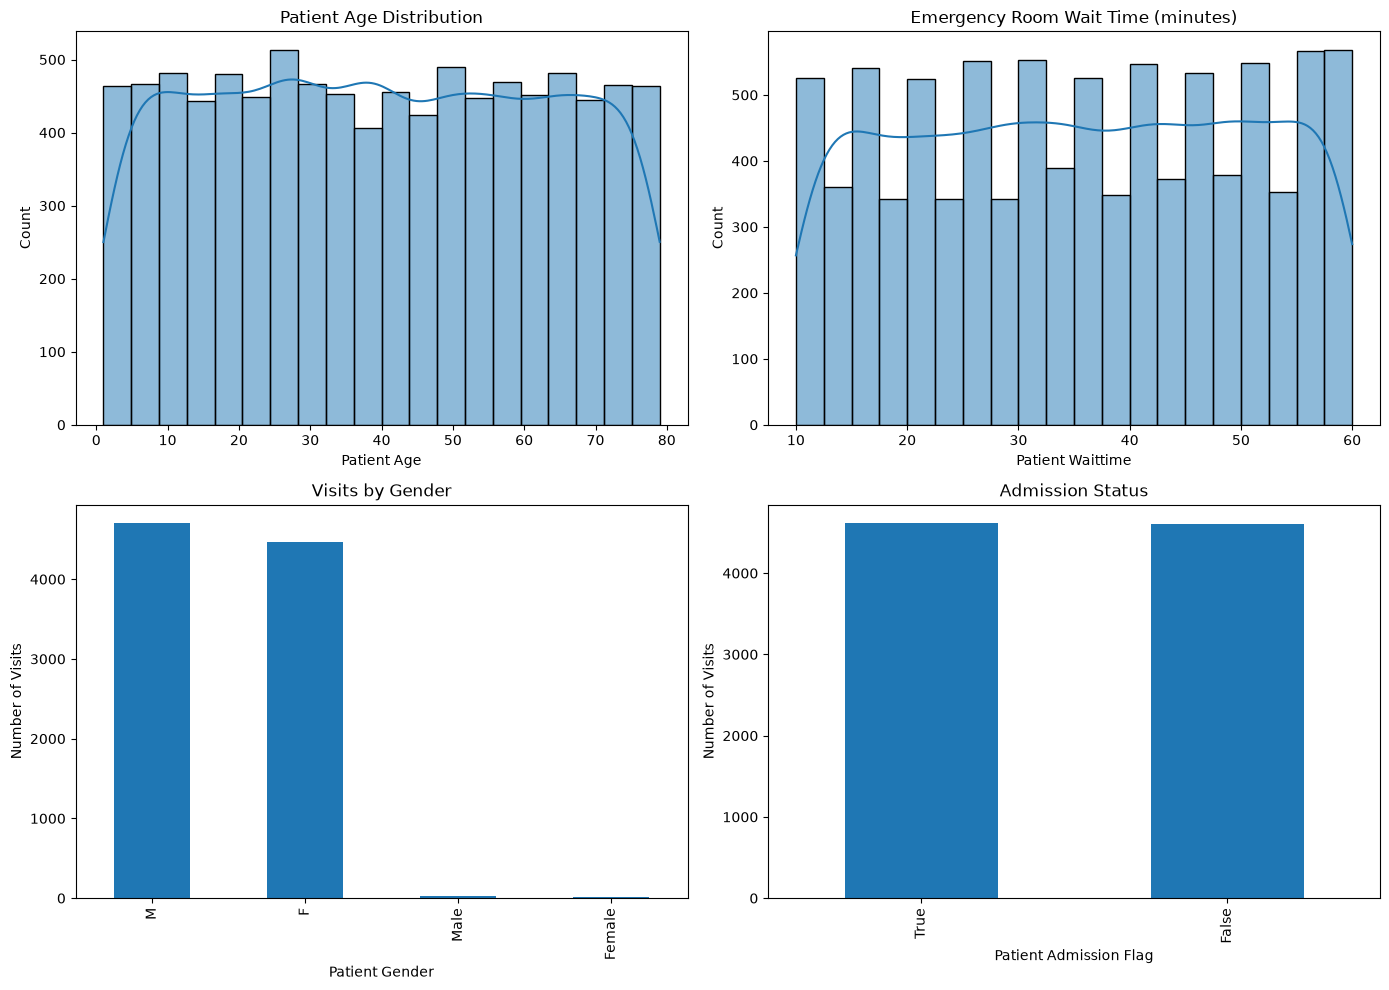

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df["Patient Age"], bins=20, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Patient Age Distribution")

sns.histplot(df["Patient Waittime"], bins=20, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Emergency Room Wait Time (minutes)")

data["Patient Gender"].value_counts().plot(kind="bar", ax=axes[1, 0])
axes[1, 0].set_title("Visits by Gender")
axes[1, 0].set_ylabel("Number of Visits")

data["Patient Admission Flag"].value_counts().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Admission Status")
axes[1, 1].set_ylabel("Number of Visits")

plt.tight_layout()
plt.show()

In [ ]:
## Step 10 – Monthly and daily visit trends

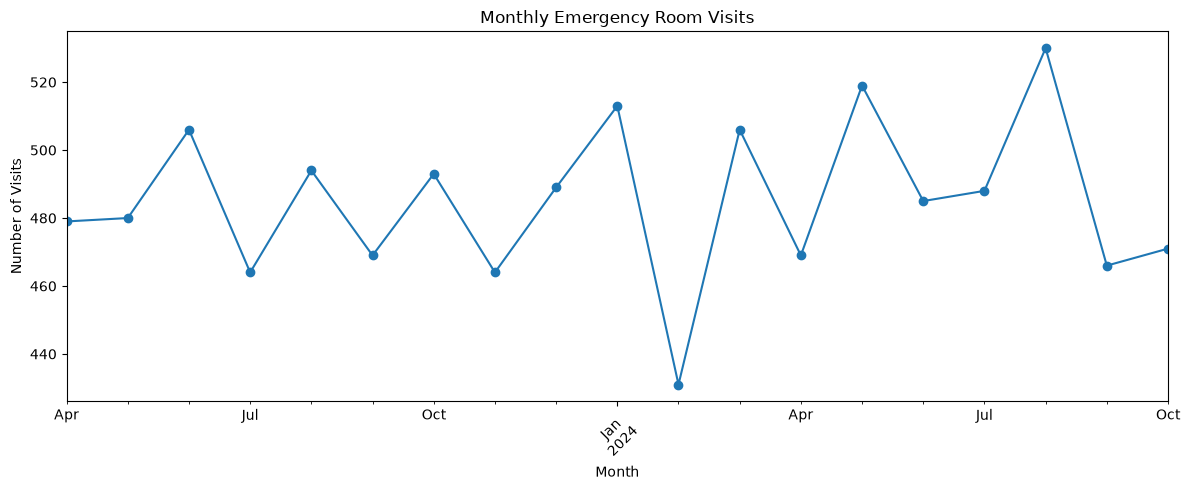

In [19]:
monthly_visits = (
    df.dropna(subset=["Patient Admission Date"])
        .set_index("Patient Admission Date")
        .resample("MS")
        .size()
)

plt.figure(figsize=(12, 5))
monthly_visits.plot(marker="o")
plt.title("Monthly Emergency Room Visits")
plt.xlabel("Month")
plt.ylabel("Number of Visits")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

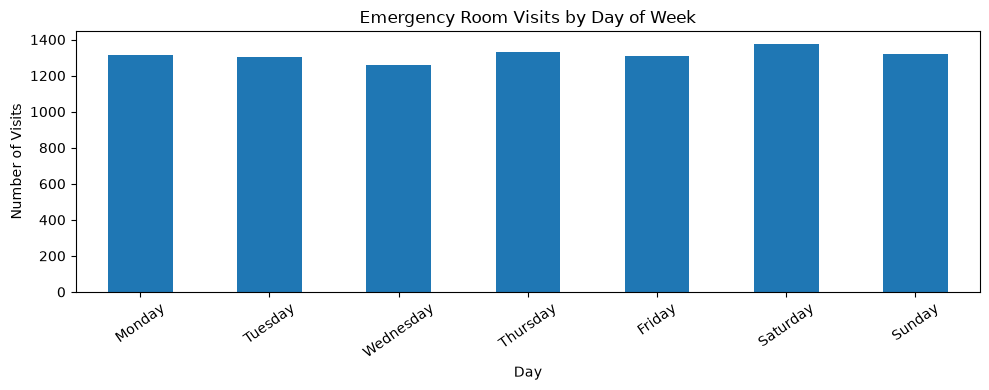

In [20]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily_visits = df["Admission Day"].value_counts().reindex(day_order)
daily_visits.plot(kind="bar", figsize=(10, 4))
plt.title("Emergency Room Visits by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Visits")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

In [ ]:
## Step 11 – Department referral analysis

,Visit_Count
Department Referral,
General Practice,1840
Orthopedics,995
Physiotherapy,276
Cardiology,248
Neurology,193
Gastroenterology,178
Renal,86


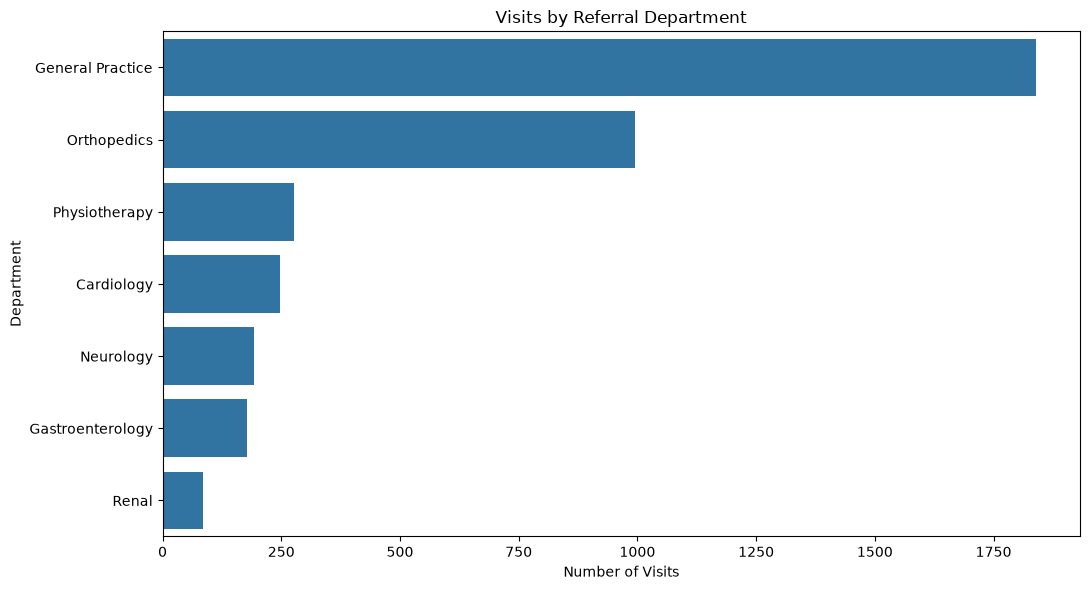

In [21]:
referral_counts = data["Department Referral"].value_counts().sort_values(ascending=False)
display(referral_counts.to_frame("Visit_Count"))

plt.figure(figsize=(11, 6))
sns.barplot(x=referral_counts.values, y=referral_counts.index)
plt.title("Visits by Referral Department")
plt.xlabel("Number of Visits")
plt.ylabel("Department")
plt.tight_layout()
plt.show()

In [ ]:
## Step 12 – Admission analysis

Patient Admission Flag,False,True
Patient Gender,,
Female,49.86,50.14
Male,50.05,49.95


,Admission_Rate_Percent
Patient Race,
Asian,51.04
African American,51.00
Native American/Alaska Native,50.40
White,50.14
Declined to Identify,49.32
Two or More Races,49.00
Pacific Islander,48.27


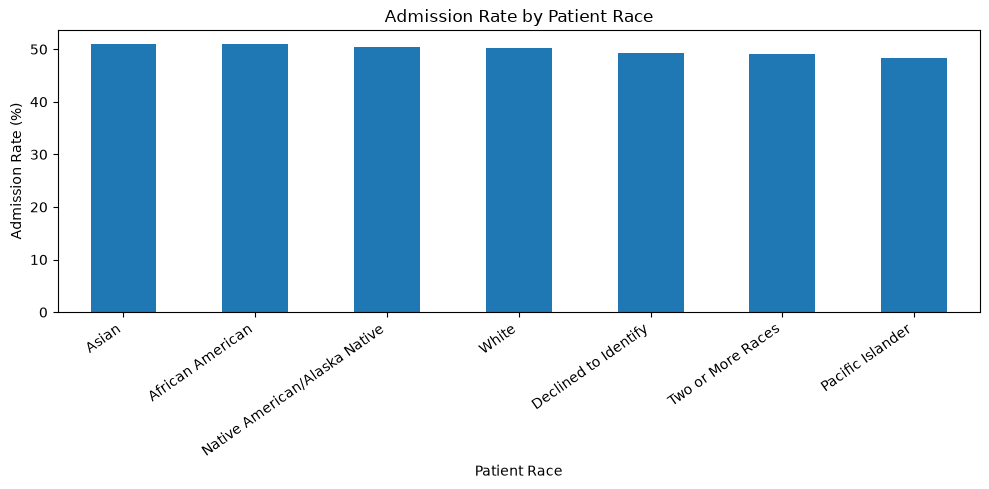

In [23]:
admission_by_gender = pd.crosstab(
    df["Patient Gender"], data["Patient Admission Flag"], normalize="index"
) * 100
display(admission_by_gender.round(2))

admission_by_race = (
    df.groupby("Patient Race")["Patient Admission Flag"]
        .apply(lambda s: (s == "Admitted").mean() * 100)
        .sort_values(ascending=False)
)
display(admission_by_race.round(2).to_frame("Admission_Rate_Percent"))


plt.figure(figsize=(10, 5))
admission_by_race.plot(kind="bar")
plt.title("Admission Rate by Patient Race")
plt.ylabel("Admission Rate (%)")
plt.xlabel("Patient Race")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()


In [ ]:
## Step 13 – Waiting time analysis

,count,mean,median
Department Referral,,,
Neurology,193,36.80,38.0
Physiotherapy,276,36.57,38.5
Gastroenterology,178,35.83,36.0
Cardiology,248,35.35,35.0
Not Recorded,5400,35.29,35.0
Orthopedics,995,34.98,34.0
General Practice,1840,34.91,35.0
Renal,86,34.70,35.0


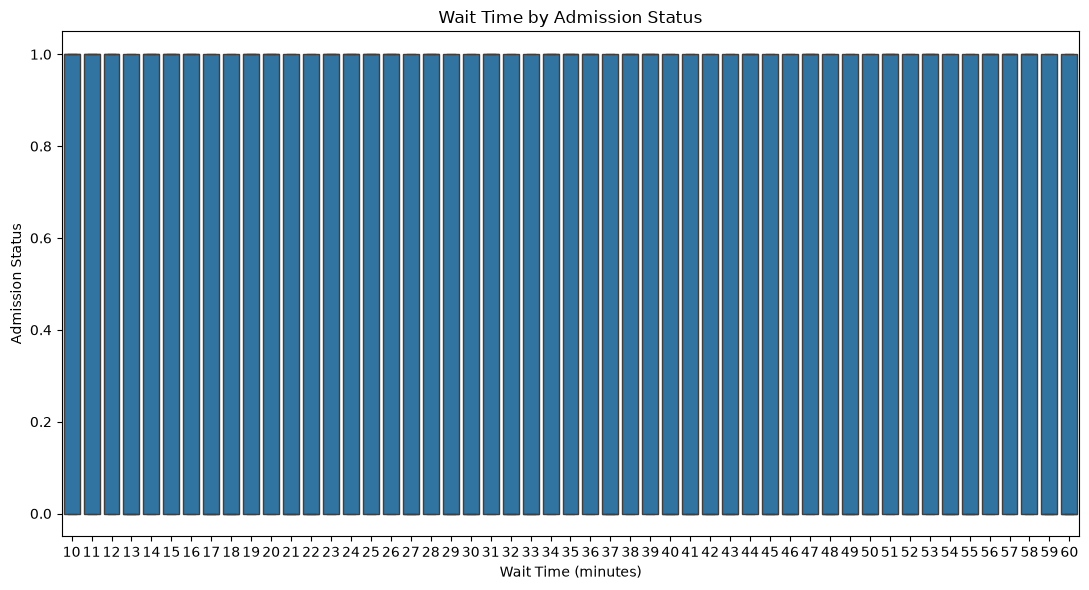

In [24]:
wait_by_department = (
    df.groupby("Department Referral")["Patient Waittime"]
        .agg(["count", "mean", "median"])
        .sort_values("mean", ascending=False)
)
display(wait_by_department.round(2))

plt.figure(figsize=(11, 6))
sns.boxplot(data=data, x="Patient Waittime", y="Patient Admission Flag")
plt.title("Wait Time by Admission Status")
plt.xlabel("Wait Time (minutes)")
plt.ylabel("Admission Status")
plt.tight_layout()
plt.show()

In [ ]:
## Step 14 – Satisfaction analysis

Records with satisfaction score: 2517


count    2517.000000
mean        4.992054
std         3.138043
min         0.000000
25%         2.000000
50%         5.000000
75%         8.000000
max        10.000000
Name: Patient Satisfaction Score, dtype: float64

,count,mean,median
Patient Admission Flag,,,
Admitted,1235,5.08,5.0
Not Admitted,1282,4.91,5.0


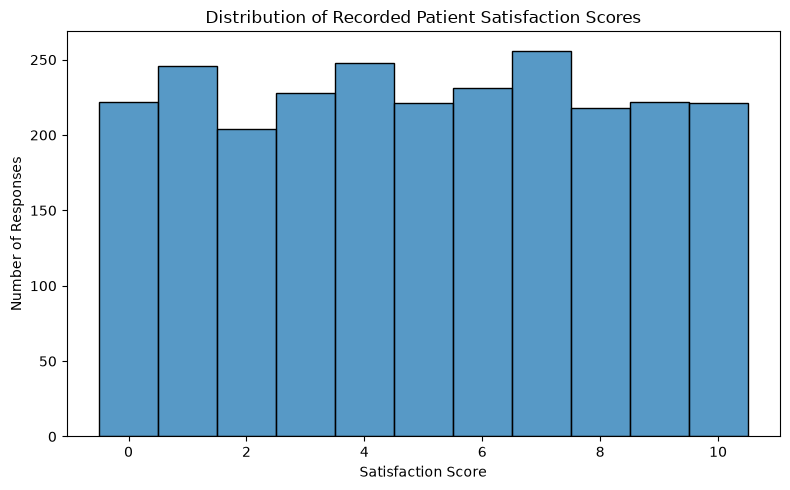

In [25]:
satisfaction_data = df.dropna(subset=["Patient Satisfaction Score"]).copy()

print("Records with satisfaction score:", len(satisfaction_data))
display(satisfaction_data["Patient Satisfaction Score"].describe())

satisfaction_by_admission = (
    satisfaction_data.groupby("Patient Admission Flag")["Patient Satisfaction Score"]
    .agg(["count", "mean", "median"])
)
display(satisfaction_by_admission.round(2))

plt.figure(figsize=(8, 5))
sns.histplot(satisfaction_data["Patient Satisfaction Score"], bins=11, discrete=True)
plt.title("Distribution of Recorded Patient Satisfaction Scores")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Responses")
plt.tight_layout()
plt.show()

In [ ]:
## Step 15 – Correlation analysis

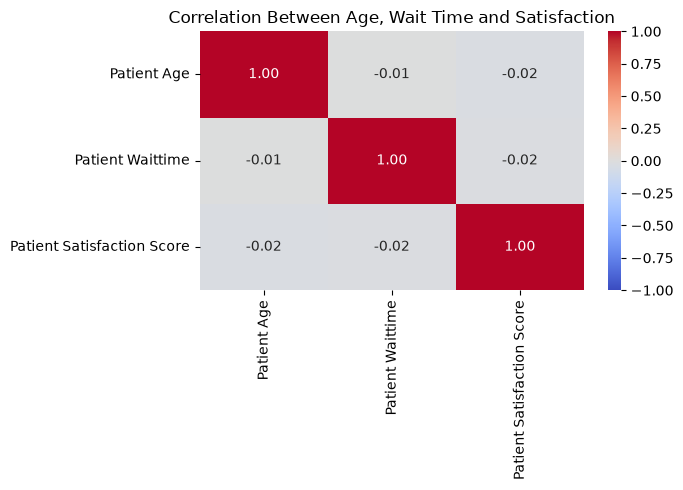

In [26]:
numeric_cols = ["Patient Age", "Patient Waittime", "Patient Satisfaction Score"]
corr = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Between Age, Wait Time and Satisfaction")
plt.tight_layout()
plt.show()

In [ ]:
## Step 16 – Export clean, aggregated outputs

In [27]:
# Save a cleaned analysis dataset. It excludes patient names and IDs.
data.to_csv("hospital_er_cleaned_analysis.csv", index=False)

# Export summary tables for portfolio documentation
kpis.to_csv("hospital_er_kpis.csv", index=False)
referral_counts.rename("Visit_Count").to_csv("hospital_er_referral_summary.csv")

print("Export complete.")

Export complete.


In [ ]:
## Step 18 – Final project conclusion template

Replace the bracketed items with values from your results:

"This project analyzed **[total visits]** emergency-room records using Python, Pandas, NumPy, Matplotlib and Seaborn. The average recorded wait time was **[X] minutes**, and **[Y]%** of visits resulted in admission. **[Department]** recorded the highest referral volume. Satisfaction analysis was limited to **[N]** records because many scores were missing. The analysis highlights operational patterns and areas for further investigation; it does not establish causes or clinical outcomes."

## Step 19 – GitHub portfolio checklist
- Upload the `.ipynb` notebook.
- Upload a README explaining objective, tools, workflow and key findings.
- Upload only anonymized charts and aggregated summary tables.
- Do not upload the original CSV because it contains patient identifiers and names unless you have explicit authorization and a compliant sharing basis.
- Run **Kernel → Restart & Run All** before publishing to ensure the notebook works from top to bottom.